
<br>
<font>
<div dir=ltr align=center>
<img src="https://cdn.freebiesupply.com/logos/large/2x/sharif-logo-png-transparent.png" width=150 height=150> <br>
<font color=0F5298 size=7>
Probability and Statistics<br>
<font color=2565AE size=5>
Electrical Engineering Department <br>

 Dr. Mojahedian, Fall 2025 <br>
<font color=3C99D size=5>
<br>
The Coupling Method: Building a Bridge Between Random Worlds

<font color=696880 size=4>

Mohammd Ehsan Moradi, Student ID: 401100993

Ali javidan Pak, Student ID: 401100671

Mahdi Zekavat, Student ID: 403101886

Ali Ghorbani, Student ID: 403102441

## Required Libraries

In [22]:
import numpy as np
from matplotlib import pyplot as plt

## Part 1: How different are two distributions?

In [23]:
# defining the required function

def calculate_tv_distance(p, q):
    diff = np.array(p) - np.array(q)
    return np.sum(diff[diff > 0])

p = [0.1 , 0.2 , 0.3 , 0.4]
q = [0.4 , 0.3 , 0.2 , 0.1]
print(calculate_tv_distance(p, q))


0.4


## Part 2: Building a bridge using Coupling

Empirical P(X≠Y) = 0.4009


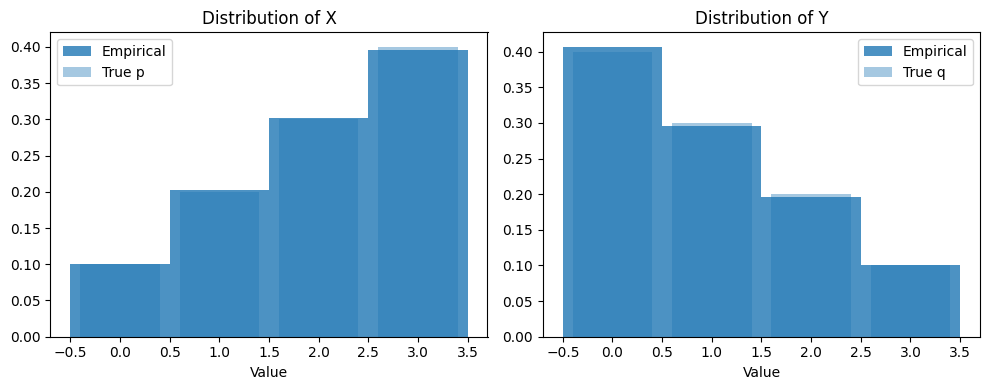

In [27]:
# defining the functions and the required variables

def sample_from_optimal_coupling(p, q, n_samples):
    p = np.array(p)
    q = np.array(q)
    values = np.arange(len(p))

    C = np.sum(np.minimum(p, q))
    pq_min = np.minimum(p, q)
    matched_dist = pq_min / C

    p_rem = (p - pq_min) / (1 - C)
    q_rem = (q - pq_min) / (1 - C)

# initializing the arrays
    X = []
    Y = []

    for _ in range(n_samples):
        U = np.random.rand()
        if U < C:
            z = np.random.choice(values, p=matched_dist)
            X.append(z)
            Y.append(z)
        else:
            x = np.random.choice(values, p=p_rem)
            y = np.random.choice(values, p=q_rem)
            X.append(x)
            Y.append(y)

    return np.array(X), np.array(Y)

# the given distributions
p = [0.1, 0.2, 0.3, 0.4]
q = [0.4, 0.3, 0.2, 0.1]

# generating samples from the distributions
X, Y = sample_from_optimal_coupling(p, q, 10000)

# count (x != y) and divide by the size of n_samples
prob_neq = np.mean(X != Y)
print(f"Empirical P(X≠Y) = {prob_neq:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# histogram of X
axes[0].hist(X, bins=np.arange(5)-0.5, density=True, alpha=0.8, label='Empirical')
axes[0].bar(range(len(p)), p, alpha=0.4, label='True p')
axes[0].set_title('Distribution of X')
axes[0].set_xlabel('Value')
axes[0].legend()

# histogram of Y
axes[1].hist(Y, bins=np.arange(5)-0.5, density=True, alpha=0.8, label='Empirical')
axes[1].bar(range(len(q)), q, alpha=0.4, label='True q')
axes[1].set_title('Distribution of Y')
axes[1].set_xlabel('Value')
axes[1].legend()

plt.tight_layout()
plt.show()

## Part 3: From strong secrecy to perfect secrecy

In [25]:
# No code for this part.

## Part 4: Coupling and convergence of Markov chains

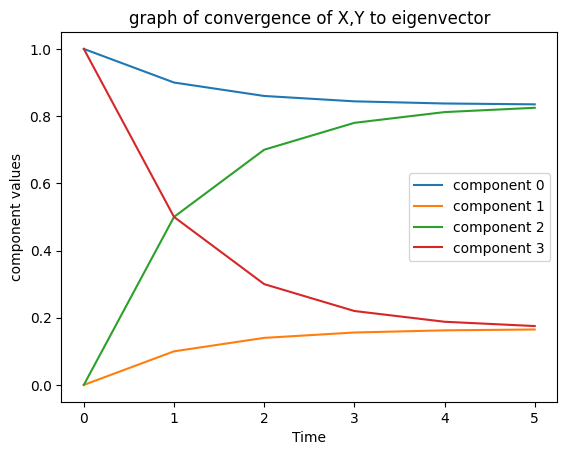

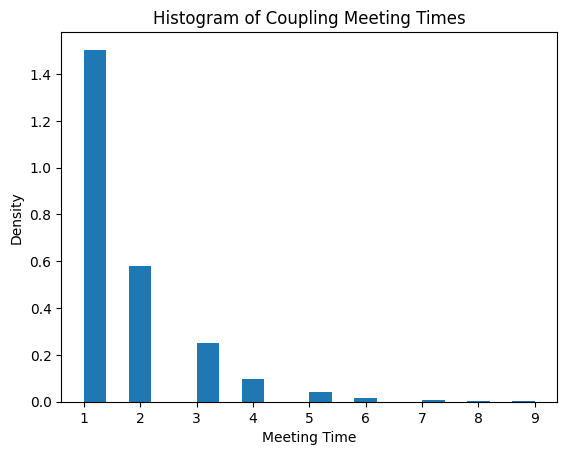

Average meeting time: 1.6772


In [26]:
T = np.array([[0.9, 0.5],
              [0.1, 0.5]])

X0 = np.array([[1], [0]])
Y0 = np.array([[0], [1]])

XY_t = [[1], [0], [0], [1]]

N = 5
for _ in range(N):
    X0, Y0= T @ X0, T @ Y0
    XY_t[0].append(X0[0,0])
    XY_t[1].append(X0[1,0])
    XY_t[2].append(Y0[0,0])
    XY_t[3].append(Y0[1,0])

t = range(N+1)
for i in range(4):
    plt.plot(t, XY_t[i], label=f'component {i}')

plt.legend()
plt.xlabel("Time")
plt.ylabel("component values")
plt.title("graph of convergence of X,Y to eigenvector")
plt.show()

#---------------------------------------------------------------------

# 0 = Sunny, 1 = Rainy

def simulate_meeting_time():
    X = 0  
    Y = 1  
    t = 0
    while X != Y:
        U = np.random.rand()
        if U < 0.5:
            X, Y = 1, 1
        elif 0.5 <= U < 0.9:
            X, Y = 0, 1
        else:
            X, Y = 0, 0
        t += 1
    return t

N = 10000
meeting_times = [simulate_meeting_time() for _ in range(N)]

plt.hist(meeting_times, bins=20, density=True)
plt.xlabel("Meeting Time")
plt.ylabel("Density")
plt.title("Histogram of Coupling Meeting Times")
plt.show()

print("Average meeting time:", np.mean(meeting_times))
